# 01 - EDA Awal Dataset Sintetis Firaza

Tujuan: memeriksa apakah data hasil `generator/generate.py` masuk akal dan memuat pola yang ingin dipelajari model
(trade-off harga vs keandalan, efek musim ramai, rekam jejak vendor), sebelum training di `02_training.ipynb`.

Asumsi data dan kamus kolom: [`docs/asumsi_data.md`](../docs/asumsi_data.md).
Label: **berhasil = 1** jika barang datang ≤ deadline **dan** cacat ≤ 3%.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from core.data import load_data
from core.features import FEATURE_COLUMNS, build_training_frame, prepare_transactions
from core.seasons import PEAK_PERIODS

# Palet: slot kategorikal 1-2 dari palet referensi tervalidasi; teks/grid netral.
BLUE, ORANGE, INK, INK2, GRID, SHADE = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e6e5e0", "#f1efe8"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": GRID,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "lines.linewidth": 2, "font.size": 10, "figure.dpi": 110,
})
pd.set_option("display.precision", 3)

d = load_data(ROOT / "data")
tx = prepare_transactions(d["transactions"])
vendors, materials, offers = d["vendors"], d["materials"], d["offers"]
{k: v.shape for k, v in d.items()}

{'vendors': (30, 5),
 'materials': (15, 9),
 'offers': (109, 6),
 'transactions': (6075, 13)}

## 1. Struktur dan kualitas data

In [2]:
tx.head()

,transaksi_id,tanggal_pesan,vendor_id,material_id,offer_id,qty,harga_satuan,total_harga,lead_time_janji,hari_tersedia,deadline,tanggal_datang,qty_cacat,berhasil,hari_telat,persen_cacat,musim_ramai
0,T00001,2024-10-01,V02,M03,O017,176,38500,6776000,11,11,2024-10-12,2024-10-12,3,1,0,0.017,0
1,T00002,2024-10-01,V03,M01,O002,158,34400,5435200,13,18,2024-10-19,2024-10-14,2,1,0,0.013,0
2,T00003,2024-10-01,V16,M07,O050,1017,2650,2695050,2,10,2024-10-11,2024-10-02,18,1,0,0.018,0
3,T00004,2024-10-01,V16,M07,O050,290,2650,768500,2,3,2024-10-04,2024-10-02,9,0,0,0.031,0
4,T00005,2024-10-01,V19,M10,O077,10,80100,801000,3,4,2024-10-05,2024-10-03,0,1,0,0.000,0


In [3]:
pd.DataFrame({
    "tipe": tx.dtypes.astype(str),
    "null": tx.isna().sum(),
    "unik": tx.nunique(),
})

,tipe,null,unik
transaksi_id,str,0,6075
tanggal_pesan,datetime64[us],0,726
vendor_id,str,0,30
material_id,str,0,15
offer_id,str,0,109
qty,int64,0,1122
harga_satuan,int64,0,790
total_harga,int64,0,5372
lead_time_janji,int64,0,16
hari_tersedia,int64,0,28


In [4]:
checks = {
    "transaksi_id unik": tx["transaksi_id"].is_unique,
    "offer_id valid": tx["offer_id"].isin(offers["offer_id"]).all(),
    "datang > pesan": (tx["tanggal_datang"] > tx["tanggal_pesan"]).all(),
    "qty_cacat <= qty": (tx["qty_cacat"] <= tx["qty"]).all(),
    "deadline terisi": tx["deadline"].notna().all(),
    "rentang tanggal": f"{tx['tanggal_pesan'].min().date()} s.d. {tx['tanggal_pesan'].max().date()}",
}
pd.Series(checks, name="hasil")

transaksi_id unik                          True
offer_id valid                             True
datang > pesan                             True
qty_cacat <= qty                           True
deadline terisi                            True
rentang tanggal      2024-10-01 s.d. 2026-09-30
Name: hasil, dtype: object

In [5]:
tx[["qty", "harga_satuan", "total_harga", "lead_time_janji", "hari_tersedia", "hari_telat", "persen_cacat"]].describe().T

,count,mean,std,min,25%,50%,75%,max
qty,6075.0,3.216e+02,4.302e+02,2.0,100.000,1.980e+02,3.780e+02,7.719e+03
harga_satuan,6075.0,2.088e+04,2.366e+04,110.0,2650.000,1.490e+04,3.570e+04,1.223e+05
total_harga,6075.0,3.245e+06,4.296e+06,25830.0,627875.000,1.668e+06,4.220e+06,6.230e+07
lead_time_janji,6075.0,7.260e+00,3.795e+00,2.0,4.000,7.000e+00,1.000e+01,1.700e+01
hari_tersedia,6075.0,1.243e+01,5.804e+00,2.0,8.000,1.200e+01,1.700e+01,2.900e+01
hari_telat,6075.0,1.394e+00,2.172e+00,0.0,0.000,0.000e+00,3.000e+00,1.300e+01
persen_cacat,6075.0,1.229e-02,1.315e-02,0.0,0.002,9.634e-03,1.754e-02,1.399e-01


## 2. Label dan komponen kegagalan

In [6]:
telat = tx["tanggal_datang"] > tx["deadline"]
cacat = tx["persen_cacat"] > 0.03
pd.Series({
    "berhasil": tx["berhasil"].mean(),
    "gagal: hanya telat": (telat & ~cacat).mean(),
    "gagal: hanya cacat > 3%": (~telat & cacat).mean(),
    "gagal: telat dan cacat": (telat & cacat).mean(),
}, name="proporsi").to_frame()

,proporsi
berhasil,0.780
gagal: hanya telat,0.136
gagal: hanya cacat > 3%,0.066
gagal: telat dan cacat,0.018


## 3. Pola waktu dan musim ramai

Area abu-abu = periode musim ramai (`core/seasons.py`). Dua panel terpisah karena skalanya berbeda (jumlah vs proporsi).

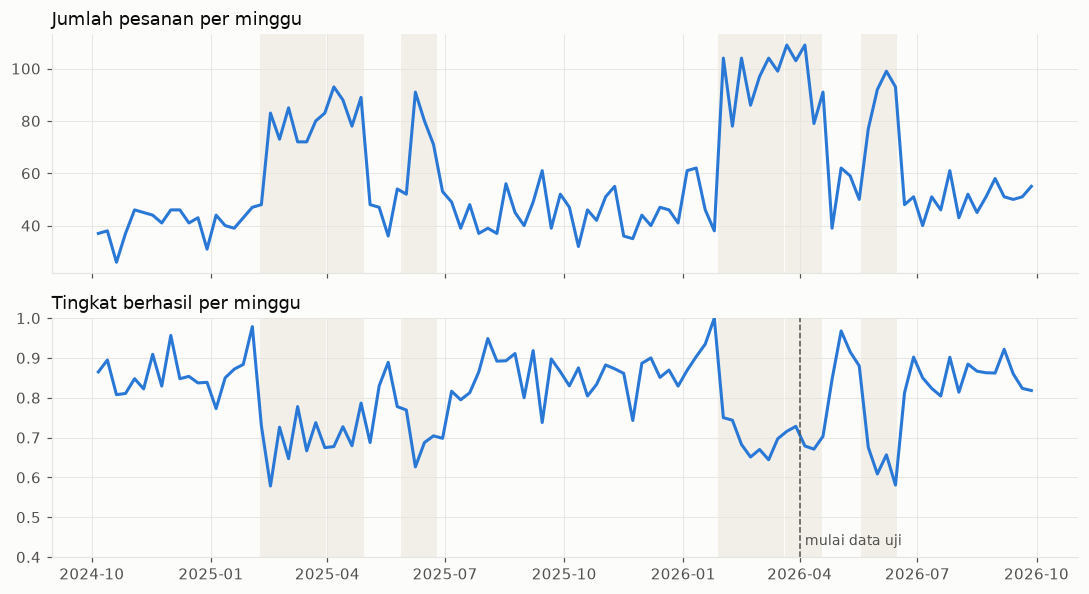

In [7]:
weekly = tx.set_index("tanggal_pesan").resample("W").agg(n=("transaksi_id", "size"), berhasil=("berhasil", "mean"))
weekly = weekly[weekly.index <= tx["tanggal_pesan"].max()]  # buang minggu terakhir yang belum penuh

fig, axes = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
for ax in axes:
    for a, b, _ in PEAK_PERIODS:
        ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color=SHADE, zorder=0, lw=0)
axes[0].plot(weekly.index, weekly["n"], color=BLUE)
axes[0].set_title("Jumlah pesanan per minggu", loc="left")
axes[1].plot(weekly.index, weekly["berhasil"], color=BLUE)
axes[1].set_ylim(0.4, 1.0)
axes[1].set_title("Tingkat berhasil per minggu", loc="left")
axes[1].axvline(pd.Timestamp("2026-04-01"), color=INK2, lw=1, ls="--")
axes[1].text(pd.Timestamp("2026-04-05"), 0.43, "mulai data uji", color=INK2, fontsize=9)
fig.tight_layout()

In [8]:
tx.groupby("musim_ramai").agg(
    jumlah=("transaksi_id", "size"),
    berhasil=("berhasil", "mean"),
    rata_qty=("qty", "mean"),
    rata_hari_telat=("hari_telat", "mean"),
    rata_cacat=("persen_cacat", "mean"),
).rename(index={0: "normal", 1: "musim ramai"})

,jumlah,berhasil,rata_qty,rata_hari_telat,rata_cacat
musim_ramai,,,,,
normal,3319,0.863,267.834,0.823,0.011
musim ramai,2756,0.680,386.283,2.083,0.014


## 4. Per kategori dan material

In [9]:
t = tx.merge(materials[["material_id", "nama_material", "kategori"]], on="material_id")
t.groupby(["kategori", "nama_material"]).agg(
    jumlah=("transaksi_id", "size"),
    berhasil=("berhasil", "mean"),
    harga_median=("harga_satuan", "median"),
    qty_median=("qty", "median"),
).sort_values("jumlah", ascending=False)

jumlah  berhasil  harga_median  \
kategori  nama_material                                               
tekstil   Handuk mandi 70x140 cm        590     0.749       38050.0   
          Sajadah polos dewasa          579     0.686       40600.0   
packaging Kotak hampers rigid box       571     0.856       18800.0   
          Kardus pengiriman             488     0.877        2750.0   
jasa      Jasa bordir nama              456     0.656        4350.0   
tekstil   Handuk muka 30x30 cm          445     0.784        8100.0   
packaging Paper bag                     412     0.830        1350.0   
jasa      Jasa printing sajadah         400     0.775       16200.0   
aksesoris Kartu ucapan cetak            338     0.861        1950.0   
packaging Plastik OPP                   330     0.739         150.0   
tekstil   Sajadah travel lipat          316     0.826       17500.0   
packaging Tas spunbond                  312     0.878        1500.0   
aksesoris Pita satin                    295     0.793       14000.0   
packaging Bubble wrap 125 cm x 50 m     285     0.667       90100.0   
tekstil   Mukena katun dewasa           258     0.729       70450.0   

                                     qty_median  
kategori  nama_material                          
tekstil   Handuk mandi 70x140 cm          177.0  
          Sajadah polos dewasa            140.0  
packaging Kotak hampers rigid box         233.0  
          Kardus pengiriman               481.5  
jasa      Jasa bordir nama                140.0  
tekstil   Handuk muka 30x30 cm            347.0  
packaging Paper bag                       304.5  
jasa      Jasa printing sajadah           119.0  
aksesoris Kartu ucapan cetak              348.0  
packaging Plastik OPP                    1195.0  
tekstil   Sajadah travel lipat            113.0  
packaging Tas spunbond                    285.0  
aksesoris Pita satin                       47.0  
packaging Bubble wrap 125 cm x 50 m        12.0  
tekstil   Mukena katun dewasa              70.5

## 5. Trade-off harga vs keberhasilan

Pertanyaan inti use case: apakah vendor termurah selalu terbaik? Harga dibandingkan **di dalam material yang sama**
(peringkat harga penawaran, 1 = termurah).

In [10]:
o = offers.assign(rank_harga=offers.groupby("material_id")["harga_satuan"].rank(method="min"))
t = tx.merge(o[["offer_id", "rank_harga"]], on="offer_id")
t["kelompok_harga"] = pd.cut(t["rank_harga"], [0, 1, 3, 100], labels=["termurah", "peringkat 2-3", "peringkat 4+"])
t.groupby("kelompok_harga", observed=True).agg(jumlah=("transaksi_id", "size"), berhasil=("berhasil", "mean"))

,jumlah,berhasil
kelompok_harga,,
termurah,1754,0.781
peringkat 2-3,2388,0.745
peringkat 4+,1933,0.823


Korelasi harga relatif vs berhasil (vendor dengan >= 20 transaksi): 0.492


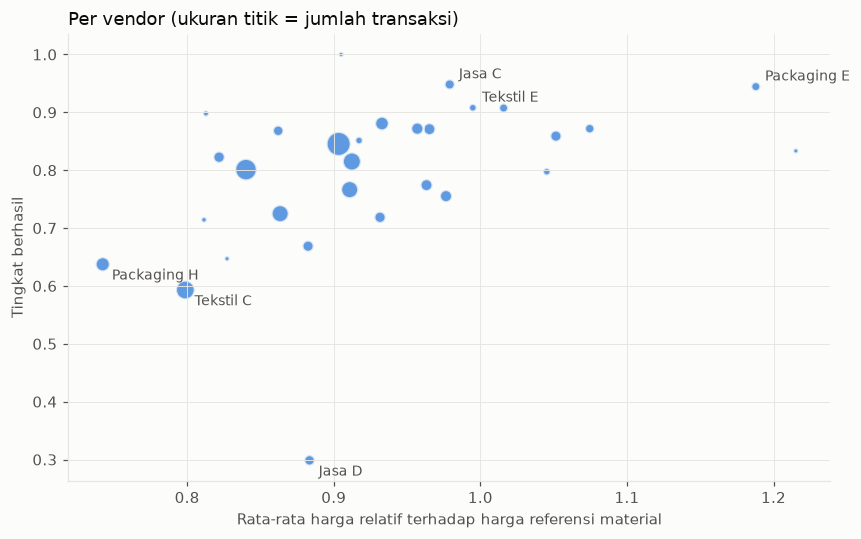

In [11]:
ref = ((materials["harga_ref_min"] + materials["harga_ref_max"]) / 2).set_axis(materials["material_id"])
per_vendor = (tx.assign(harga_relatif=tx["harga_satuan"] / tx["material_id"].map(ref))
                .groupby("vendor_id")
                .agg(harga_relatif=("harga_relatif", "mean"), berhasil=("berhasil", "mean"), n=("transaksi_id", "size")))
per_vendor = per_vendor.join(vendors.set_index("vendor_id")["nama_vendor"])

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(per_vendor["harga_relatif"], per_vendor["berhasil"], s=np.clip(per_vendor["n"] / 3, 12, 250),
           color=BLUE, alpha=0.75, edgecolor="#fcfcfb", linewidth=1.5)
enough = per_vendor[per_vendor["n"] >= 20]
for name, r in enough.nlargest(3, "berhasil").iterrows():
    ax.annotate(r["nama_vendor"], (r["harga_relatif"], r["berhasil"]), xytext=(6, 4), textcoords="offset points", fontsize=9, color=INK2)
for name, r in enough.nsmallest(3, "berhasil").iterrows():
    ax.annotate(r["nama_vendor"], (r["harga_relatif"], r["berhasil"]), xytext=(6, -10), textcoords="offset points", fontsize=9, color=INK2)
ax.set_xlabel("Rata-rata harga relatif terhadap harga referensi material")
ax.set_ylabel("Tingkat berhasil")
ax.set_title("Per vendor (ukuran titik = jumlah transaksi)", loc="left")
fig.tight_layout()
print("Korelasi harga relatif vs berhasil (vendor dengan >= 20 transaksi):",
      round(per_vendor[per_vendor["n"] >= 20][["harga_relatif", "berhasil"]].corr().iloc[0, 1], 3))

## 6. Kelonggaran waktu dan ukuran pesanan

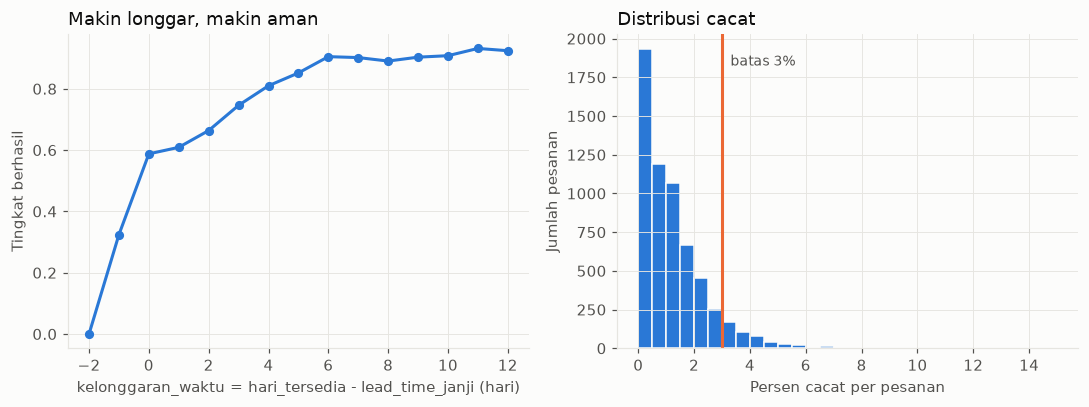

In [12]:
t = tx.assign(kelonggaran=tx["hari_tersedia"] - tx["lead_time_janji"])
g = t.groupby(t["kelonggaran"].clip(-2, 12))["berhasil"].agg(["mean", "size"])

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].plot(g.index, g["mean"], color=BLUE, marker="o", markersize=5)
axes[0].set_xlabel("kelonggaran_waktu = hari_tersedia - lead_time_janji (hari)")
axes[0].set_ylabel("Tingkat berhasil")
axes[0].set_title("Makin longgar, makin aman", loc="left")
axes[1].hist(tx["persen_cacat"] * 100, bins=np.arange(0, 15.5, 0.5), color=BLUE, edgecolor="#fcfcfb", linewidth=1)
axes[1].axvline(3, color=ORANGE, lw=2)
axes[1].text(3.3, axes[1].get_ylim()[1] * 0.9, "batas 3%", color=INK2, fontsize=9)
axes[1].set_xlabel("Persen cacat per pesanan")
axes[1].set_ylabel("Jumlah pesanan")
axes[1].set_title("Distribusi cacat", loc="left")
fig.tight_layout()

## 7. Jumlah transaksi per vendor

Vendor dengan < 5 transaksi akan ditandai **data terbatas** di hasil rekomendasi.

,nama_vendor,kategori,tanggal_bergabung,transaksi
vendor_id,,,,
V21,Jasa B,jasa,2026-08-23,2
V30,Aksesoris E,aksesoris,2025-11-03,12


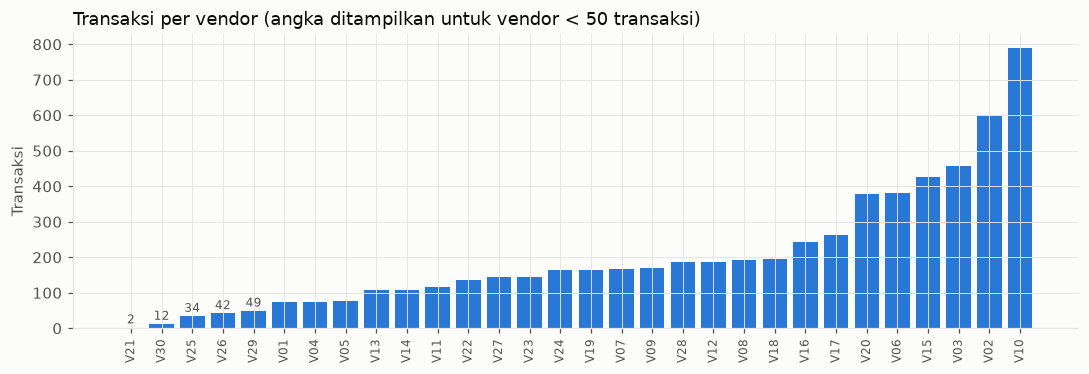

In [13]:
counts = tx["vendor_id"].value_counts().reindex(vendors["vendor_id"], fill_value=0).sort_values()
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(range(len(counts)), counts.to_numpy(), color=BLUE, width=0.8)
for i, n in enumerate(counts.to_numpy()):
    if n < 50:
        ax.text(i, n + 12, str(n), ha="center", fontsize=8, color=INK2)
ax.set_xticks(range(len(counts)), counts.index, rotation=90, fontsize=8)
ax.set_ylabel("Transaksi")
ax.set_title("Transaksi per vendor (angka ditampilkan untuk vendor < 50 transaksi)", loc="left")
fig.tight_layout()
vendors.set_index("vendor_id").loc[counts[counts < 20].index, ["nama_vendor", "kategori", "tanggal_bergabung"]].assign(transaksi=counts[counts < 20])

## 8. Fitur model (anti-leakage)

Fitur dibangun oleh `core.features.build_training_frame`. Rekam jejak vendor untuk pesanan tanggal *t* hanya memakai
transaksi vendor itu yang **sudah datang sebelum t**.

In [14]:
tf = build_training_frame(d["transactions"], offers, materials)
print(tf.shape, "| NaN:", int(tf[FEATURE_COLUMNS].isna().sum().sum()))
num = [c for c in FEATURE_COLUMNS if c != "kategori"]
tf[num + ["berhasil"]].corr()["berhasil"].drop("berhasil").sort_values(key=abs, ascending=False).to_frame("korelasi_dgn_label")

(6075, 23) | NaN: 0


,korelasi_dgn_label
kelonggaran_waktu,0.311
tingkat_cacat,-0.238
berhasil_musim_ramai,0.222
musim_ramai,-0.219
tingkat_berhasil_10,0.206
hari_tersedia,0.199
rata_hari_telat,-0.186
bulan,0.107
harga_relatif,0.070
qty,-0.031


In [15]:
train = tf["tanggal_pesan"] < "2026-04-01"
pd.DataFrame({
    "baris": [train.sum(), (~train).sum()],
    "tingkat_berhasil": [tf.loc[train, "berhasil"].mean(), tf.loc[~train, "berhasil"].mean()],
    "periode": ["Okt 2024 - Mar 2026 (bulan 1-18)", "Apr - Sep 2026 (bulan 19-24)"],
}, index=["train", "test"])

,baris,tingkat_berhasil,periode
train,4492,0.778,Okt 2024 - Mar 2026 (bulan 1-18)
test,1583,0.786,Apr - Sep 2026 (bulan 19-24)


## 9. Validasi generator dengan sifat tersembunyi

`vendors_hidden.csv` **hanya** dipakai di sini dan saat evaluasi, tidak pernah oleh model atau aplikasi.
Jika generator benar, tingkat berhasil teramati harus searah dengan keandalan/kualitas sebenarnya.

In [16]:
hidden = pd.read_csv(ROOT / "data" / "vendors_hidden.csv").set_index("vendor_id")
chk = per_vendor.join(hidden)
chk = chk[chk["n"] >= 20]
chk[["berhasil", "true_reliability", "true_defect_rate", "price_factor"]].corr()["berhasil"].to_frame("korelasi_dgn_berhasil_teramati")

,korelasi_dgn_berhasil_teramati
berhasil,1.000
true_reliability,0.596
true_defect_rate,-0.933
price_factor,0.524


## Ringkasan temuan

1. **Kualitas data.** 6.075 transaksi (Okt 2024 – Sep 2026), 30 vendor, 15 material, 109 penawaran. Tidak ada nilai kosong, semua cek integritas lolos.
2. **Label.** 78,0% pesanan berhasil. Kegagalan lebih sering karena **telat** (13,6% hanya telat) daripada cacat (6,6% hanya cacat, 1,8% keduanya). Kelas cukup seimbang, jadi ROC-AUC tetap informatif tanpa resampling.
3. **Musim ramai** mencakup 45% transaksi. Tingkat berhasil turun dari 86,3% ke 68,0%, rata-rata keterlambatan naik dari 0,8 ke 2,1 hari, dan qty pesanan rata-rata naik dari 268 ke 386. Fitur `musim_ramai` dan `berhasil_musim_ramai` relevan.
4. **Termurah belum tentu terbaik.** Penawaran termurah per material berhasil 78,1%, sedangkan penawaran peringkat harga 4+ berhasil 82,3%. Di tingkat vendor, harga relatif berkorelasi positif dengan keberhasilan (r = 0,49), tetapi tidak mutlak: Tekstil C murah dan sering gagal, sedangkan Jasa D gagal meski harganya rata-rata. Ini trade-off yang perlu dibantu sistem.
5. **Fitur terkuat** (korelasi linear dengan label): `kelonggaran_waktu` (0,31), `tingkat_cacat` (−0,24), `berhasil_musim_ramai` (0,22), `musim_ramai` (−0,22), `tingkat_berhasil_10` (0,21). `qty` dan `rasio_qty` hampir 0 secara linear. Efek kapasitas di generator bersifat nonlinear, jadi akan dicek dengan model pohon.
6. **Data terbatas.** V21 (2 transaksi, bergabung Agu 2026) dan V30 (12 transaksi). Rekam jejaknya dihaluskan ke prior, dan V21 akan ditandai "data terbatas" di rekomendasi.
7. **Split waktu.** Train bulan 1–18: 4.492 baris (berhasil 77,8%). Test bulan 19–24: 1.583 baris (78,6%). Distribusi label kedua periode mirip.
8. **Validasi generator.** Tingkat berhasil teramati per vendor searah dengan sifat tersembunyi (r = 0,60 dengan keandalan, −0,93 dengan tingkat cacat), jadi rekam jejak historis memang membawa sinyal tentang vendor.

**Catatan untuk Minggu 2 (training):**
- Data historis hanya memuat vendor yang **dipilih owner** (bias seleksi). Model belajar P(berhasil) dari vendor yang pernah dipakai; vendor yang jarang dipilih punya ketidakpastian lebih besar.
- `kategori` perlu one-hot. Fitur numerik perlu scaling untuk Logistic Regression.
- Baseline = `tingkat_berhasil_semua` (rata-rata historis yang dihaluskan), sudah dipakai `core.ranking` selama model belum dilatih.
